In [1]:

# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

print("Librerías importadas correctamente")


Librerías importadas correctamente


In [2]:

from google.colab import files

# Seleccionar y cargar el archivo
uploaded = files.upload()

# Leer el archivo Excel
df = pd.read_excel("Dataset_Maestro_SustainCrop.xlsx")

print("Dataset cargado correctamente")


Saving Dataset_Maestro_SustainCrop.xlsx to Dataset_Maestro_SustainCrop.xlsx
Dataset cargado correctamente


In [3]:

# Mostrar las primeras 5 filas
display(df.head())

# Dimensiones del dataset
print("Dimensiones del dataset:", df.shape)

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)


,DOI,HIPERVÍNCULO SINTETIZADO,AÑO,REVISTA,AUTORES,INSTITUCIONES_COLABORADORAS,TIPO DE CULTIVO,DATASET,RESUMEN DE ARTÍCULO,ENTE FINANCIADOR,CONVOCATORIA,RELEVANCIA,CATEGORÍA SUSTAINCROP,ENFOQUE SOSTENIBILIDAD UE
0,https://doi.org/10.5281/zenodo.19406165,https://doi.org/10.5281/zenodo.19406165,2026,Zenodo (CERN European Organization for Nuclear...,Claudia Milena Serpa-Imbett; Lorena Aguayo-Ull...,"Universidad del Sinú, Universidad de Zaragoza,...",NaN,Sí,"Multisensor, Multitemporal Forage Dataset: Meg...",NaN,NaN,Alta,Investigación & Conocimiento,agrosilvicultura
1,https://doi.org/10.29312/remexca.v17i6.4153,https://doi.org/10.29312/remexca.v17i6.4153,2026,Revista Mexicana de Ciencias Agrícolas,Laura Sánchez‐Castillo; Edmar Meléndez-Jaramil...,"Autonomous University of Tamaulipas, Universid...",NaN,No,Soil is an essential and strategic resource fo...,NaN,NaN,Media,Investigación & Conocimiento,Agropastoral system
2,https://doi.org/10.1038/s41598-026-70051-1,https://doi.org/10.1038/s41598-026-70051-1,2026,Scientific Reports,Paola Vanessa Sierra Baquero; Filipa Monteiro;...,"University of Lisbon, Corporación Colombiana d...",NaN,No,Abstract Essential oils are increasingly recog...,"Fundação para a Ciência e a Tecnologia, Minist...",doi.org/10.54499/LA/P/0092/2020; UID/00329/202...,Alta,Investigación & Conocimiento,Gestión sostenible de plagas con aceites esenc...
3,https://doi.org/10.1371/journal.pone.0358469,https://doi.org/10.1371/journal.pone.0358469,2026,PLoS ONE,Juan Pablo Narvaez-Herrera; Joaquín Angulo-Ari...,"Universidad de Antioquia, Corporación Colombia...",NaN,Sí,Silvopastoral systems and other tree-based lan...,"Ministerio de Ciencia, Tecnología e Innovación...",No. 20230030-20-21,Alta,Investigación & Conocimiento,Silvopastoral (agrosilviculture)
4,https://doi.org/10.3389/feart.2026.1910946,https://doi.org/10.3389/feart.2026.1910946,2026,Frontiers in Earth Science,Edwin Sebastián Caceres Garcia; Christian José...,"Universidad Nacional de Colombia, Corporación ...",NaN,Sí,"In tropical agricultural regions, accurate est...",NaN,NaN,Media,Investigación & Conocimiento,climate-smart agriculture


Dimensiones del dataset: (63, 14)

Columnas:
['DOI', 'HIPERVÍNCULO SINTETIZADO', 'AÑO', 'REVISTA', 'AUTORES', 'INSTITUCIONES_COLABORADORAS', 'TIPO DE CULTIVO', 'DATASET', 'RESUMEN DE ARTÍCULO', 'ENTE FINANCIADOR', 'CONVOCATORIA', 'RELEVANCIA', 'CATEGORÍA SUSTAINCROP', 'ENFOQUE SOSTENIBILIDAD UE']

Tipos de datos:
DOI                             object
HIPERVÍNCULO SINTETIZADO        object
AÑO                              int64
REVISTA                         object
AUTORES                         object
INSTITUCIONES_COLABORADORAS     object
TIPO DE CULTIVO                float64
DATASET                         object
RESUMEN DE ARTÍCULO             object
ENTE FINANCIADOR                object
CONVOCATORIA                    object
RELEVANCIA                      object
CATEGORÍA SUSTAINCROP           object
ENFOQUE SOSTENIBILIDAD UE       object
dtype: object


In [4]:

# Cantidad de valores faltantes por columna
print("Valores faltantes:")
display(df.isnull().sum())

# Porcentaje de valores faltantes
print("\nPorcentaje de valores faltantes:")
display((df.isnull().mean() * 100).round(2))


Valores faltantes:


,0
DOI,0
HIPERVÍNCULO SINTETIZADO,0
AÑO,0
REVISTA,0
AUTORES,0
INSTITUCIONES_COLABORADORAS,0
TIPO DE CULTIVO,63
DATASET,0
RESUMEN DE ARTÍCULO,0
ENTE FINANCIADOR,40



Porcentaje de valores faltantes:


,0
DOI,0.00
HIPERVÍNCULO SINTETIZADO,0.00
AÑO,0.00
REVISTA,0.00
AUTORES,0.00
INSTITUCIONES_COLABORADORAS,0.00
TIPO DE CULTIVO,100.00
DATASET,0.00
RESUMEN DE ARTÍCULO,0.00
ENTE FINANCIADOR,63.49


In [5]:

# 1. Estadísticas de las variables numéricas
print("ESTADÍSTICAS DE VARIABLES NUMÉRICAS")

display(df.describe())

# 2. Frecuencias de variables categóricas
print("\nFRECUENCIAS DE VARIABLES CATEGÓRICAS")

columnas_categoricas = [
    "REVISTA",
    "DATASET",
    "RELEVANCIA",
    "CATEGORÍA SUSTAINCROP"
]

for columna in columnas_categoricas:
    print(f"\nFrecuencia de {columna}:")
    display(df[columna].value_counts())

# 3. Medidas de tendencia central del año
print("\nMEDIDAS DE TENDENCIA CENTRAL DEL AÑO")

print("Media:", df["AÑO"].mean())
print("Mediana:", df["AÑO"].median())
print("Moda:", df["AÑO"].mode().tolist())


ESTADÍSTICAS DE VARIABLES NUMÉRICAS


,AÑO,TIPO DE CULTIVO
count,63.000000,0.0
mean,2025.492063,NaN
std,1.162214,NaN
min,2019.000000,NaN
25%,2025.000000,NaN
50%,2026.000000,NaN
75%,2026.000000,NaN
max,2026.000000,NaN



FRECUENCIAS DE VARIABLES CATEGÓRICAS

Frecuencia de REVISTA:


,count
REVISTA,
Corporación Colombiana de Investigación Agropecuaria (Agrosavia) eBooks,5
Memorias Seminario Científico Cenicafé,3
Revista de la Academia Colombiana de Ciencias Exactas Físicas y Naturales,3
Avances Técnicos Cenicafé,3
Revista Cenicafé,2
Revista Colombiana de Entomología,2
Agriculture,2
Revista de Ciencias Agrícolas,2
Florida Entomologist,2



Frecuencia de DATASET:


,count
DATASET,
No,36
Sí,27



Frecuencia de RELEVANCIA:


,count
RELEVANCIA,
Alta,47
Media,16



Frecuencia de CATEGORÍA SUSTAINCROP:


,count
CATEGORÍA SUSTAINCROP,
Investigación & Conocimiento,55
Industria & Mercado,3
Sector Primario,3
Sociedad Civil & Territorio,2



MEDIDAS DE TENDENCIA CENTRAL DEL AÑO
Media: 2025.4920634920634
Mediana: 2026.0
Moda: [2026]


In [6]:

# Caracterización de los resúmenes

textos = df["RESUMEN DE ARTÍCULO"].dropna()

# Longitud de cada resumen
longitud_caracteres = textos.astype(str).str.len()
longitud_palabras = textos.astype(str).str.split().str.len()

print("CARACTERIZACIÓN DE LOS TEXTOS")

print("\nCantidad de textos:", len(textos))

print("\nLongitud en caracteres:")
print(longitud_caracteres.describe())

print("\nCantidad de palabras:")
print(longitud_palabras.describe())

# Identificar el resumen más corto y más largo
print("\nResumen más corto:")
print(textos.iloc[longitud_caracteres.argmin()][:300])

print("\nResumen más largo:")
print(textos.iloc[longitud_caracteres.argmax()][:300])


CARACTERIZACIÓN DE LOS TEXTOS

Cantidad de textos: 63

Longitud en caracteres:
count      63.000000
mean     1702.079365
std      1079.731199
min       307.000000
25%      1377.000000
50%      1531.000000
75%      1838.000000
max      9163.000000
Name: RESUMEN DE ARTÍCULO, dtype: float64

Cantidad de palabras:
count      63.000000
mean      240.571429
std       146.255159
min        50.000000
25%       193.000000
50%       230.000000
75%       250.500000
max      1236.000000
Name: RESUMEN DE ARTÍCULO, dtype: float64

Resumen más corto:
El Avance Técnico presenta los primeros resultados del control de la broca con drones de aspersión, así como los resultados de la calidad física de las aspersiones en el cultivo del café con drones de primera generación, y se brindan recomendaciones para el ajuste de algunos parámetros operativos de

Resumen más largo:
Multisensor, Multitemporal Forage Dataset: Megathyrsus maximus cv. Mombasa under Tropical Silvopastoral Conditions (Wet and Dry Seasons, 

In [7]:

# Crear una copia del dataset original
df_limpio = df.copy()

# Función para transformar caracteres
def transformar_caracteres(texto):

    if pd.isna(texto):
        return ""

    texto = str(texto)

    # Normalización Unicode
    texto = unicodedata.normalize("NFC", texto)

    # Convertir a minúsculas
    texto = texto.lower()

    # Eliminar espacios repetidos
    texto = re.sub(r"\s+", " ", texto)

    # Eliminar espacios al inicio y al final
    texto = texto.strip()

    return texto


# Aplicar transformación a los resúmenes
df_limpio["RESUMEN_TRANSFORMADO"] = (
    df_limpio["RESUMEN DE ARTÍCULO"].apply(transformar_caracteres)
)

# Comparar textos originales y transformados
comparacion = df_limpio[
    ["RESUMEN DE ARTÍCULO", "RESUMEN_TRANSFORMADO"]
].head(3)

display(comparacion)

print("\nTransformación realizada correctamente")


,RESUMEN DE ARTÍCULO,RESUMEN_TRANSFORMADO
0,"Multisensor, Multitemporal Forage Dataset: Meg...","multisensor, multitemporal forage dataset: meg..."
1,Soil is an essential and strategic resource fo...,soil is an essential and strategic resource fo...
2,Abstract Essential oils are increasingly recog...,abstract essential oils are increasingly recog...



Transformación realizada correctamente


In [8]:

from collections import Counter

# Unir todos los resúmenes transformados
texto_completo = " ".join(df_limpio["RESUMEN_TRANSFORMADO"])

# Identificar caracteres que no sean letras, números o espacios
caracteres_especiales = Counter(
    caracter for caracter in texto_completo
    if not caracter.isalnum() and not caracter.isspace()
)

# Mostrar los caracteres encontrados
print("CARACTERES ESPECIALES EN EL DATASET:\n")

for caracter, frecuencia in caracteres_especiales.most_common():
    print(repr(caracter), ":", frecuencia)


CARACTERES ESPECIALES EN EL DATASET:

',' : 1090
'.' : 808
'-' : 288
')' : 263
'(' : 258
'%' : 110
':' : 67
'/' : 56
'–' : 37
'±' : 31
';' : 20
'—' : 20
'_' : 11
'°' : 10
'=' : 9
'•' : 9
'’' : 8
'‐' : 8
'"' : 6
"'" : 6
'®' : 6
'+' : 6
'“' : 6
'”' : 6
'×' : 5
'<' : 5
'>' : 3
'$' : 3
'′' : 2
'≥' : 2
'¿' : 1
'?' : 1
'¡' : 1
'!' : 1
'≤' : 1
'~' : 1
'|' : 1
'&' : 1
'⁺' : 1
'@' : 1


In [9]:

# Función para limpiar caracteres especiales
def limpiar_caracteres(texto):

    if pd.isna(texto):
        return ""

    texto = str(texto)

    # Unificar diferentes tipos de guiones
    texto = re.sub(r"[–—‐]", "-", texto)

    # Normalizar comillas
    texto = re.sub(r"[‘’“”]", "'", texto)

    # Conservar letras, números, espacios y símbolos científicos
    texto = re.sub(r"[^\w\s%°±×+\-=<>/]", " ", texto)

    # Eliminar guiones bajos
    texto = texto.replace("_", " ")

    # Eliminar espacios repetidos
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()


# Aplicar limpieza
df_limpio["RESUMEN_LIMPIO"] = (
    df_limpio["RESUMEN_TRANSFORMADO"].apply(limpiar_caracteres)
)

# Comparar resultados
display(
    df_limpio[
        ["RESUMEN_TRANSFORMADO", "RESUMEN_LIMPIO"]
    ].head(3)
)

print("Limpieza de caracteres completada")


,RESUMEN_TRANSFORMADO,RESUMEN_LIMPIO
0,"multisensor, multitemporal forage dataset: meg...",multisensor multitemporal forage dataset megat...
1,soil is an essential and strategic resource fo...,soil is an essential and strategic resource fo...
2,abstract essential oils are increasingly recog...,abstract essential oils are increasingly recog...


Limpieza de caracteres completada


In [10]:

# Instalar recursos de NLTK
!pip install nltk

import nltk

# Descargar recursos de tokenización
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK preparado correctamente")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


NLTK preparado correctamente


In [11]:

from nltk.tokenize import word_tokenize

# Función de tokenización
def tokenizar_texto(texto):

    if pd.isna(texto):
        return []

    return word_tokenize(str(texto))


# Aplicar tokenización
df_limpio["TOKENS"] = df_limpio["RESUMEN_LIMPIO"].apply(
    tokenizar_texto
)

# Mostrar los primeros 3 resultados
for i in range(3):
    print(f"\nRESUMEN {i+1}")
    print(df_limpio["TOKENS"].iloc[i][:30])

# Cantidad de tokens por resumen
df_limpio["CANTIDAD_TOKENS"] = df_limpio["TOKENS"].apply(len)

print("\nCantidad promedio de tokens:")
print(df_limpio["CANTIDAD_TOKENS"].mean())



RESUMEN 1
['multisensor', 'multitemporal', 'forage', 'dataset', 'megathyrsus', 'maximus', 'cv', 'mombasa', 'under', 'tropical', 'silvopastoral', 'conditions', 'wet', 'and', 'dry', 'seasons', 'colombian', 'caribbean', 'overview', 'this', 'dataset', 'comprises', '400', 'structured', 'observations', 'of', 'individual', 'megathyrsus', 'maximus', 'cv']

RESUMEN 2
['soil', 'is', 'an', 'essential', 'and', 'strategic', 'resource', 'for', 'the', 'sustainability', 'of', 'agricultural', 'production', 'on', 'the', 'planet', 'however', 'it', 'faces', 'progressive', 'degradation', 'derived', 'from', 'unsustainable', 'management', 'practices', 'and', 'the', 'effects', 'of']

RESUMEN 3
['abstract', 'essential', 'oils', 'are', 'increasingly', 'recognized', 'as', 'ecofriendly', 'alternatives', 'to', 'synthetic', 'pesticides', 'especially', 'in', 'tropical', 'regions', 'with', 'high', 'pest', 'pressure', 'and', 'limited', 'crop', 'protection', 'resources', 'this', 'study', 'evaluates', 'native', 'and']


In [12]:

import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

# Obtener stopwords en ambos idiomas
stopwords_ingles = set(stopwords.words('english'))
stopwords_espanol = set(stopwords.words('spanish'))

# Unir ambos conjuntos
stopwords_combinadas = stopwords_ingles.union(stopwords_espanol)

print("Stopwords en inglés:", len(stopwords_ingles))
print("Stopwords en español:", len(stopwords_espanol))
print("Total de stopwords:", len(stopwords_combinadas))


Stopwords en inglés: 198
Stopwords en español: 313
Total de stopwords: 504


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [13]:

# Función para eliminar stopwords
def eliminar_stopwords(tokens):

    return [
        palabra for palabra in tokens
        if palabra.lower() not in stopwords_combinadas
    ]


# Aplicar eliminación de stopwords
df_limpio["TOKENS_SIN_STOPWORDS"] = (
    df_limpio["TOKENS"].apply(eliminar_stopwords)
)

# Comparar resultados
for i in range(3):

    print(f"\nRESUMEN {i+1}")

    print("Antes:")
    print(df_limpio["TOKENS"].iloc[i][:20])

    print("\nDespués:")
    print(df_limpio["TOKENS_SIN_STOPWORDS"].iloc[i][:20])


# Calcular promedio de tokens restantes
df_limpio["TOKENS_RESTANTES"] = (
    df_limpio["TOKENS_SIN_STOPWORDS"].apply(len)
)

print("\nPromedio de tokens después de eliminar stopwords:")
print(df_limpio["TOKENS_RESTANTES"].mean())



RESUMEN 1
Antes:
['multisensor', 'multitemporal', 'forage', 'dataset', 'megathyrsus', 'maximus', 'cv', 'mombasa', 'under', 'tropical', 'silvopastoral', 'conditions', 'wet', 'and', 'dry', 'seasons', 'colombian', 'caribbean', 'overview', 'this']

Después:
['multisensor', 'multitemporal', 'forage', 'dataset', 'megathyrsus', 'maximus', 'cv', 'mombasa', 'tropical', 'silvopastoral', 'conditions', 'wet', 'dry', 'seasons', 'colombian', 'caribbean', 'overview', 'dataset', 'comprises', '400']

RESUMEN 2
Antes:
['soil', 'is', 'an', 'essential', 'and', 'strategic', 'resource', 'for', 'the', 'sustainability', 'of', 'agricultural', 'production', 'on', 'the', 'planet', 'however', 'it', 'faces', 'progressive']

Después:
['soil', 'essential', 'strategic', 'resource', 'sustainability', 'agricultural', 'production', 'planet', 'however', 'faces', 'progressive', 'degradation', 'derived', 'unsustainable', 'management', 'practices', 'effects', 'climate', 'change', 'within']

RESUMEN 3
Antes:
['abstract', 'e

In [14]:

# Conservar palabras de negación
negaciones = {
    "no", "not", "nor", "never", "neither",
    "nunca", "jamas", "jamás", "tampoco"
}

stopwords_combinadas = stopwords_combinadas - negaciones

# Volver a aplicar la eliminación
df_limpio["TOKENS_SIN_STOPWORDS"] = (
    df_limpio["TOKENS"].apply(eliminar_stopwords)
)

# Actualizar cantidad de tokens
df_limpio["TOKENS_RESTANTES"] = (
    df_limpio["TOKENS_SIN_STOPWORDS"].apply(len)
)

print("Promedio actualizado:")
print(df_limpio["TOKENS_RESTANTES"].mean())


Promedio actualizado:
165.04761904761904


In [17]:

# Filtrar tokens: conservar únicamente palabras
def filtrar_tokens(tokens):
    return [
        palabra for palabra in tokens
        if palabra.isalpha() and len(palabra) > 1
    ]

# Aplicar filtro
df_limpio["TOKENS_FINALES"] = (
    df_limpio["TOKENS_SIN_STOPWORDS"].apply(filtrar_tokens)
)

# Unir todas las palabras
todos_los_tokens = []

for lista in df_limpio["TOKENS_FINALES"]:
    todos_los_tokens.extend(lista)

# Calcular frecuencias
frecuencias = Counter(todos_los_tokens)

# Crear tabla de las 20 palabras más frecuentes
tabla_frecuencias = pd.DataFrame(
    frecuencias.most_common(20),
    columns=["Palabra", "Frecuencia"]
)

display(tabla_frecuencias)


,Palabra,Frecuencia
0,soil,56
1,using,40
2,coffee,39
3,study,36
4,control,35
5,management,34
6,colombia,32
7,systems,29
8,chemical,29
9,results,29


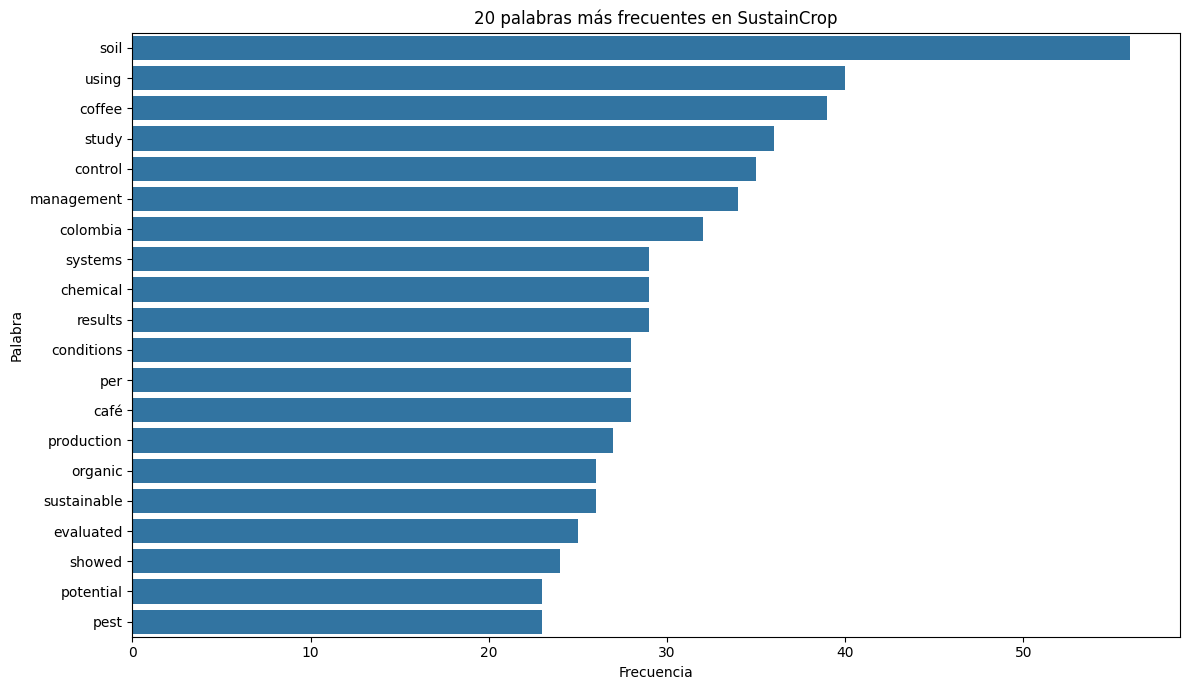

In [18]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=tabla_frecuencias,
    x="Frecuencia",
    y="Palabra"
)

plt.title("20 palabras más frecuentes en SustainCrop")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")

plt.tight_layout()
plt.show()


In [19]:

from sklearn.feature_extraction.text import TfidfVectorizer

print("Scikit-learn preparado correctamente")


Scikit-learn preparado correctamente


In [20]:

# Convertir las listas de tokens en textos
documentos = df_limpio["TOKENS_FINALES"].apply(
    lambda tokens: " ".join(tokens)
)

# Crear el vectorizador TF-IDF
vectorizador = TfidfVectorizer(
    lowercase=False,
    max_features=1000
)

# Aplicar la vectorización
matriz_tfidf = vectorizador.fit_transform(documentos)

# Obtener los nombres de las palabras
palabras_tfidf = vectorizador.get_feature_names_out()

print("VECTORACIÓN TF-IDF COMPLETADA")
print("Cantidad de documentos:", matriz_tfidf.shape[0])
print("Cantidad de términos:", matriz_tfidf.shape[1])
print("Dimensiones de la matriz:", matriz_tfidf.shape)


VECTORACIÓN TF-IDF COMPLETADA
Cantidad de documentos: 63
Cantidad de términos: 1000
Dimensiones de la matriz: (63, 1000)


In [21]:

# Convertir una pequeña muestra a DataFrame
matriz_muestra = pd.DataFrame(
    matriz_tfidf[:3].toarray(),
    columns=palabras_tfidf
)

# Mostrar los términos con mayor peso en el primer artículo
pesos = matriz_muestra.iloc[0].sort_values(
    ascending=False
).head(10)

print("10 términos con mayor peso TF-IDF del primer artículo:")
display(pesos.to_frame(name="Peso TF-IDF"))


10 términos con mayor peso TF-IDF del primer artículo:


,Peso TF-IDF
imagery,0.295249
dataset,0.274160
columns,0.253071
spectral,0.253071
tussock,0.210892
tussocks,0.210892
variables,0.156464
products,0.153396
file,0.147625
dates,0.147625


In [22]:

# Calcular el promedio TF-IDF de cada término
promedio_tfidf = np.asarray(
    matriz_tfidf.mean(axis=0)
).flatten()

# Crear tabla de términos representativos
tabla_tfidf = pd.DataFrame({
    "Palabra": palabras_tfidf,
    "Peso_promedio": promedio_tfidf
})

# Ordenar de mayor a menor
tabla_tfidf = tabla_tfidf.sort_values(
    by="Peso_promedio",
    ascending=False
)

# Mostrar los 20 términos principales
display(tabla_tfidf.head(20))


,Palabra,Peso_promedio
852,soil,0.043093
161,coffee,0.035575
117,café,0.034370
201,control,0.025585
528,management,0.022751
946,using,0.021625
905,systems,0.020794
149,chemical,0.020334
163,colombia,0.020044
651,pest,0.019815


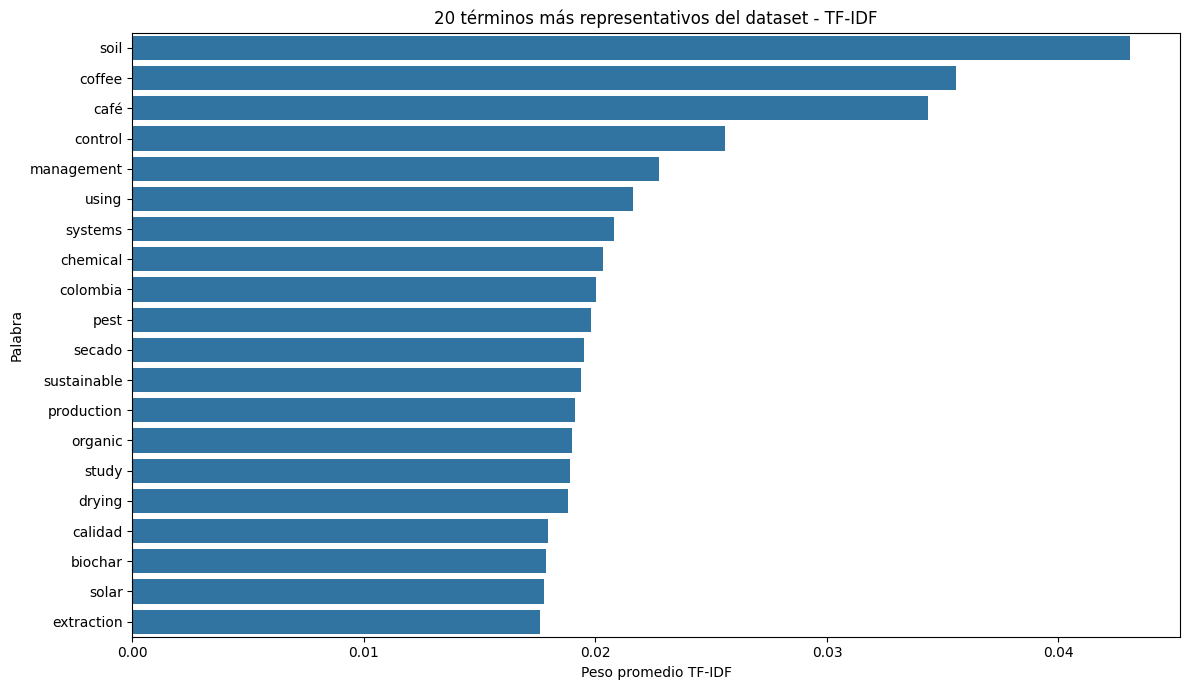

In [23]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=tabla_tfidf.head(20),
    x="Peso_promedio",
    y="Palabra"
)

plt.title("20 términos más representativos del dataset - TF-IDF")
plt.xlabel("Peso promedio TF-IDF")
plt.ylabel("Palabra")

plt.tight_layout()
plt.show()


In [24]:

# Preparar copia para exportar
df_export = df_limpio.copy()

# Convertir listas de tokens en texto para Excel
columnas_lista = [
    "TOKENS",
    "TOKENS_SIN_STOPWORDS",
    "TOKENS_FINALES"
]

for columna in columnas_lista:
    df_export[columna] = df_export[columna].apply(
        lambda x: " ".join(x) if isinstance(x, list) else x
    )

# Crear matriz TF-IDF
df_matriz = pd.DataFrame(
    matriz_tfidf.toarray(),
    columns=palabras_tfidf
)

# Agregar identificador DOI
df_matriz.insert(0, "DOI", df["DOI"].values)

# Crear archivo Excel con varias hojas
nombre_archivo = "Dataset_SustainCrop_Procesado.xlsx"

with pd.ExcelWriter(nombre_archivo, engine="openpyxl") as writer:

    df_export.to_excel(
        writer, sheet_name="Datos procesados", index=False
    )

    df_matriz.to_excel(
        writer, sheet_name="Matriz TF-IDF", index=False
    )

    tabla_frecuencias.to_excel(
        writer, sheet_name="Frecuencias", index=False
    )

    tabla_tfidf.to_excel(
        writer, sheet_name="Pesos TF-IDF", index=False
    )

print("Archivo Excel generado correctamente")

# Descargar archivo
from google.colab import files
files.download(nombre_archivo)


Archivo Excel generado correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>